# Activity recognition with a hidden Markov model

Formative 2, Machine Learning Techniques. Four hidden states — standing, walking, jumping, and still — are decoded from windowed accelerometer and gyroscope features.

The data is 200 Sensor Logger recordings from one iPhone 16 Pro, 50 per activity, plus a second session on the same phone in `data/unseen/` that is kept for testing only. `python -m src.convert` turns the Sensor Logger zips in `data/raw/` into the CSVs under `data/processed/` and writes `data/manifest.csv`. Video links for the four activities are listed in the README.

The model is a diagonal Gaussian HMM in NumPy: Baum-Welch for learning, Viterbi for the label sequence. Nothing is imported from an HMM library.

In [1]:
from pathlib import Path
import sys

import numpy as np

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data import recording_rows
from src.evaluate import confusion_matrix, per_class_metrics
from src.experiment import (
    decoded_example,
    fit_model,
    load_splits,
    score_items,
    score_with_params,
)
from src.features import ACTIVITIES, FEATURE_NAMES, HOP, TARGET_FS, WINDOW
from src.hmm import self_test
from src.plots import (
    plot_decoded,
    plot_emissions,
    plot_heatmap,
    plot_likelihood,
    plot_raw_magnitude,
)

# src.plots selects the Agg backend for scripts. Switch back so figures show here.
%matplotlib inline

check = self_test()
print(
    f"Implementation check passed. "
    f"Viterbi accuracy on a known 2-state chain: {check['viterbi_accuracy']:.2f}. "
    f"EM log-likelihood {check['loglik_start']:.2f} -> {check['loglik_end']:.2f} "
    f"in {check['iterations']} iterations, and it did not fall."
)

Implementation check passed. Viterbi accuracy on a known 2-state chain: 1.00. EM log-likelihood -848.97 -> -848.94 in 5 iterations, and it did not fall.


## Data

Every recording comes from Sensor Logger on one iPhone 16 Pro, which sampled the accelerometer and the gyroscope every 10 ms (100 Hz). There are 50 recordings per activity, each between 5.6 and 9.9 seconds long, which gives 393 to 439 seconds per activity against the 90-second minimum. On iOS the Sensor Logger accelerometer stream is user acceleration: gravity is already removed, and the unit is m/s². The gyroscope is in rad/s. `src/convert.py` puts both on one clock that starts at 0 s and labels every row with the folder the recording came from.

Every file is interpolated onto a 50 Hz grid before windowing. With one phone this is a downsample, but it fixes the window at 50 samples whatever rate a phone records at, so an export from a second phone at 40 or 60 Hz would drop in without other changes.

The window is 1.0 second (50 samples) and the hop is 0.5 second. A step is about half a second, so the window covers at least one step and the native frequency bin is 1 Hz. The label of a window is the majority activity inside it.

The last 10 recordings of each activity, by start time, are held out. They were taken later in the session than every training file of the same activity. The scaler and the HMM are fit on the other 40. The unseen session in `data/unseen/` is a third split. Nothing touches it until its own section near the end, and its two continuous recordings are the only files that change activity.

standing  50 files,  438.5 s in total, 5.58-9.87 s each
walking   50 files,  393.0 s in total, 7.21-8.68 s each
jumping   50 files,  399.0 s in total, 6.71-9.46 s each
still     50 files,  438.0 s in total, 7.65-9.93 s each
Sample rates (Hz): ['100']


Single-activity files: 160 train, 40 test
Mixed sequences: 0 train, 0 test
Unseen session: 20 single-activity files, 2 continuous recordings
Window 1.0s, hop 0.5s, rate 50 Hz


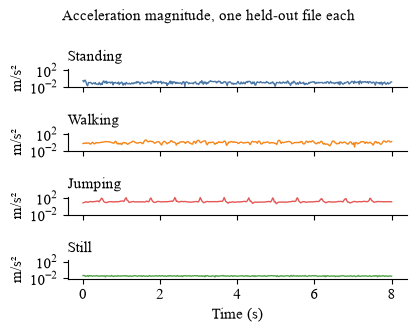

In [2]:
rows = [row for row in recording_rows(ROOT) if row["split"] != "unseen"]
for name in ACTIVITIES:
    seconds = [float(row["duration_s"]) for row in rows if row["activity"] == name]
    print(
        f"{name:9} {len(seconds)} files, {sum(seconds):6.1f} s in total, "
        f"{min(seconds):.2f}-{max(seconds):.2f} s each"
    )
print("Sample rates (Hz):", sorted({row["sample_rate_hz"] for row in rows}))

splits = load_splits(ROOT)
train_n = sum(1 for item in splits["train"] if item["meta"]["activity"] != "mixed")
test_n = sum(1 for item in splits["test"] if item["meta"]["activity"] != "mixed")
mixed_train = sum(1 for item in splits["train"] if item["meta"]["activity"] == "mixed")
mixed_test = sum(1 for item in splits["test"] if item["meta"]["activity"] == "mixed")
print(f"Single-activity files: {train_n} train, {test_n} test")
print(f"Mixed sequences: {mixed_train} train, {mixed_test} test")
unseen_single_n = sum(1 for item in splits["unseen"] if item["meta"]["activity"] != "mixed")
unseen_mixed_n = len(splits["unseen"]) - unseen_single_n
print(f"Unseen session: {unseen_single_n} single-activity files, {unseen_mixed_n} continuous recordings")
print(f"Window {WINDOW / TARGET_FS:.1f}s, hop {HOP / TARGET_FS:.1f}s, rate {TARGET_FS:.0f} Hz")

examples = {}
for name in ACTIVITIES:
    candidates = [item for item in splits["test"] if item["meta"]["activity"] == name]
    match = max(candidates, key=lambda item: item["duration"])
    mask = match["time"] <= 8.0
    examples[name] = (match["time"][mask], match["magnitude"][mask])
plot_raw_magnitude(examples);

## Features

Gravity in a window is the mean acceleration vector, and it is removed before the magnitude features. Otherwise every activity looks like 1 g and the tilt of the phone dominates the Gaussian.

Six features are time-domain: mean, variance, and RMS of the dynamic magnitude; signal magnitude area; the correlation of the two horizontal axes; and the mean gyroscope magnitude. Three are taken from an FFT. The dominant frequency is the peak on the axis that moves the most, after the FFT is zero-padded, and it is reported as 0 Hz when no bin clears the noise floor. Taking that peak on the magnitude would rectify the signal and hide the cadence. Spectral energy stays on the magnitude, from 0.15 to 8 Hz, because that quantity is total motion rather than the motion of one axis. The same peak is computed for the gyroscope.

Six features are sizes: the mean, variance, and RMS of the dynamic magnitude, SMA, spectral energy, and the mean gyroscope magnitude. On this data they span about seven orders of magnitude. The training mean of spectral energy is below 0.001 for still and above 10,000 for jumping. A z-score on that scale is set by jumping, and standing and still end up closer together than the variance floor of one Gaussian. So those six features go through log10 first. Then every feature is z-scored with the mean and scale of the training windows only, because a correlation, a frequency, and a spectral energy do not share a unit. The section after the held-out evaluation shows what happens without the log.

In [3]:
raw = []
owners = []
for item in splits["train"]:
    if item["meta"]["activity"] == "mixed":
        continue
    raw.append(item["features"])
    owners.append(np.full(len(item["features"]), item["meta"]["activity"]))
raw = np.concatenate(raw)
owners = np.concatenate(owners)
header = f"{'feature':22} " + " ".join(f"{name:>10}" for name in ACTIVITIES)
print("Training mean of each raw feature")
print(header)
for col, feature in enumerate(FEATURE_NAMES):
    means = [raw[owners == name, col].mean() for name in ACTIVITIES]
    print(f"{feature:22} " + " ".join(f"{value:10.4f}" for value in means))
print()
print("Share of windows where a frequency peak clears the noise floor, and its median")
print(header)
for feature in ("acc_dom_freq", "gyro_dom_freq"):
    col = FEATURE_NAMES.index(feature)
    peaks = [raw[owners == name, col] for name in ACTIVITIES]
    print(f"{feature + ' share':22} " + " ".join(f"{np.mean(p > 0):10.2f}" for p in peaks))
    print(
        f"{feature + ' Hz':22} "
        + " ".join(f"{np.median(p[p > 0]) if np.any(p > 0) else 0.0:10.2f}" for p in peaks)
    )

Training mean of each raw feature
feature                  standing    walking    jumping      still
acc_mag_mean               0.0955     1.0646    13.2608     0.0089
acc_mag_var                0.0025     0.2453   136.2592     0.0000
acc_mag_rms                0.1068     1.1714    17.5036     0.0098
sma                        0.1385     1.5669    17.2002     0.0134
acc_xy_corr                0.0172     0.3467     0.4140    -0.0134
acc_dom_freq               3.7454     0.3943     0.6246     0.5445
acc_spectral_energy        0.0999    19.0251 13454.4654     0.0008
gyro_mag_mean              0.0224     0.2901     3.2825     0.0010
gyro_dom_freq              1.1985     0.6804     1.2544     0.7893

Share of windows where a frequency peak clears the noise floor, and its median
feature                  standing    walking    jumping      still
acc_dom_freq share           0.54       0.27       0.47       0.12
acc_dom_freq Hz              7.52       1.27       1.37       4.30
gyro_dom_freq s

The size features carry the separation. Each activity sits about an order of magnitude above the one below it: still, then standing, then walking, then jumping.

The frequency features are weaker on real data than they were meant to be. A one-second window holds about two strides, and the acceleration peak clears the noise floor in only about a quarter of walking windows. Standing finds a peak more often than walking does, at several hertz, which is small tremor rather than a cadence. The gyroscope peak does better. It fires in most jumping windows near 1.5 Hz, the jump rate, and in about half of walking windows near 1 Hz, the stride rate. A two-second window would roughly double the share of walking windows with a peak, at the price of a slower response to a change of activity.

## Which algorithm the metrics use

Baum-Welch is the learner. The recordings are labeled, and those labels initialize each state, but the deployed phone will not have a label. EM is what updates the start vector, the transitions, and the Gaussians from the windows themselves. The stop test is a relative change in training log-likelihood below 10⁻⁶.

Viterbi is the decoder the table scores. Sensitivity, specificity, and accuracy count one hard label per window, which is the label a live display would show. Forward-backward posteriors are what the E-step uses, and they are the right object when a window should stay uncertain. They are not what the confusion matrix counts. An error in the Viterbi path is an off-diagonal cell.

## The HMM code

The model lives in `src/hmm.py`, so this notebook and `python -m src.experiment` run one implementation. The cell below prints its core from that file: the Gaussian emission density, the forward and backward passes in log space, the E-step, Baum-Welch with its log-likelihood stopping test, and Viterbi.

In [4]:
import inspect

from src.hmm import GaussianHMM

for method in (
    GaussianHMM._log_emit,
    GaussianHMM._forward,
    GaussianHMM._backward,
    GaussianHMM.expectations,
    GaussianHMM.fit,
    GaussianHMM.viterbi,
):
    print(inspect.getsource(method))

    def _log_emit(self, obs):
        """Log density of each frame under each state's diagonal Gaussian."""
        variance = np.maximum(self.var, self.var_floor)
        delta = obs[:, None, :] - self.mu[None, :, :]
        quad = np.sum(delta * delta / variance[None, :, :], axis=2)
        log_det = np.sum(np.log(variance), axis=1)
        width = obs.shape[1]
        return -0.5 * (width * np.log(2.0 * np.pi) + log_det[None, :] + quad)

    def _forward(self, log_b):
        log_alpha = np.empty_like(log_b)
        log_alpha[0] = np.log(self.pi) + log_b[0]
        log_A = np.log(self.A)
        for t in range(1, len(log_b)):
            arrived = log_alpha[t - 1][:, None] + log_A
            log_alpha[t] = log_b[t] + logsumexp(arrived, axis=0)
        return log_alpha

    def _backward(self, log_b):
        log_beta = np.empty_like(log_b)
        log_beta[-1] = 0.0
        log_A = np.log(self.A)
        for t in range(len(log_b) - 2, -1, -1):
            leave = log_A + log_b[t + 

Iterations: 4
Log-likelihood: 9189.7 -> 9471.1
Monotonic: True. Final relative change: 0.000e+00
State order after alignment: ['standing', 'walking', 'jumping', 'still']


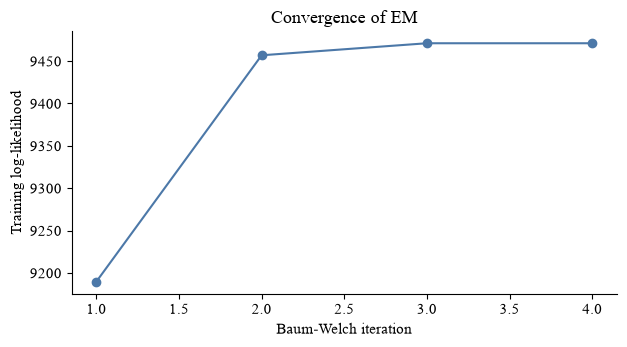

In [5]:
model, scaler, history, order, start_params = fit_model(splits)
rose = all(history[i] <= history[i + 1] + 1e-3 for i in range(len(history) - 1))
rel = abs(history[-1] - history[-2]) / (abs(history[-2]) + 1e-8)
print(f"Iterations: {len(history)}")
print(f"Log-likelihood: {history[0]:.1f} -> {history[-1]:.1f}")
print(f"Monotonic: {rose}. Final relative change: {rel:.3e}")
print("State order after alignment:", [ACTIVITIES[i] for i in order.tolist()])
plot_likelihood(history);

Rows sum to [1. 1. 1. 1.]


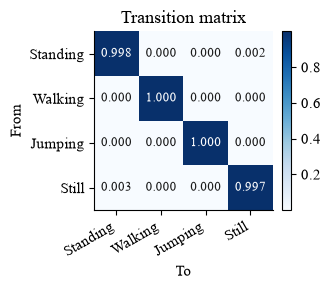

In [6]:
plot_heatmap(model.A, ACTIVITIES, "Transition matrix", "To", "From", ".3f")
print("Rows sum to", np.round(model.A.sum(axis=1), 6))

## Emission probabilities

Each state emits a diagonal Gaussian over the nine scaled features. The figure shows its mean and standard deviation on every feature. The probability of a window under a state is the product of those nine densities.

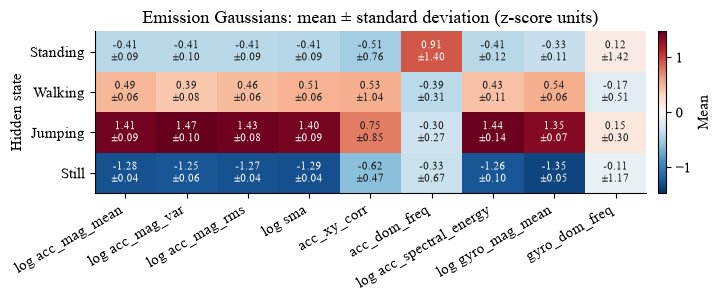

In [7]:
plot_emissions(model.mu, model.var, ACTIVITIES, FEATURE_NAMES);

## Held-out evaluation

The test files are the last 10 recordings of each activity, made later in the same session as the training files. None of them was used to fit the scaler or the model, or to name the states. A sample in the table is one window.

Activity      Windows  Sensitivity  Specificity   Accuracy
standing          138        1.000        1.000      1.000
walking           134        1.000        1.000      1.000
jumping           149        1.000        1.000      1.000
still             160        1.000        1.000      1.000
Files correct by majority vote: 40 / 40
Labeled starting point, before Baum-Welch: 1.000
No mixed recordings in the held-out set. The continuous ones are in the unseen session.


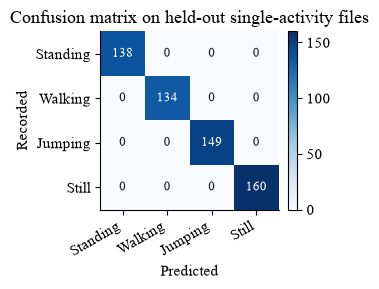

In [8]:
def decode(item):
    return model.viterbi(scaler.transform(item["features"]))

pure = [item for item in splits["test"] if item["meta"]["activity"] != "mixed"]
mixed = [item for item in splits["test"] if item["meta"]["activity"] == "mixed"]

truth = np.concatenate([item["labels"] for item in pure])
predicted = np.concatenate([decode(item) for item in pure])
matrix = confusion_matrix(truth, predicted, len(ACTIVITIES))
metrics = per_class_metrics(matrix)

print(f"{'Activity':12} {'Windows':>8} {'Sensitivity':>12} {'Specificity':>12} {'Accuracy':>10}")
for name, row in zip(ACTIVITIES, metrics):
    print(
        f"{name:12} {row['support']:8d} {row['sensitivity']:12.3f} "
        f"{row['specificity']:12.3f} {row['overall_accuracy']:10.3f}"
    )
file_hits = []
for item in pure:
    path = decode(item)
    file_hits.append(int(np.bincount(path).argmax() == np.bincount(item["labels"]).argmax()))
print(f"Files correct by majority vote: {sum(file_hits)} / {len(file_hits)}")
start_score = score_with_params(model, scaler, pure, start_params)
print(f"Labeled starting point, before Baum-Welch: {start_score['frame_accuracy']:.3f}")

if mixed:
    mixed_truth = np.concatenate([item["labels"] for item in mixed])
    mixed_pred = np.concatenate([decode(item) for item in mixed])
    mixed_acc = float(np.mean(mixed_truth == mixed_pred))
    print(f"Mixed-sequence frame accuracy: {mixed_acc:.3f} on {len(mixed_truth)} windows, {len(mixed)} files")
else:
    print("No mixed recordings in the held-out set. The continuous ones are in the unseen session.")
plot_heatmap(
    matrix,
    ACTIVITIES,
    "Confusion matrix on held-out single-activity files",
    "Predicted",
    "Recorded",
    "d",
);

A recording that changes activity is the natural test of decoded transitions. The held-out set has none, so the figure joins seven held-out files end to end: still, standing, walking, jumping, walking, standing, still. The changes in that sequence are file boundaries, not changes the phone recorded. The unseen session below has two real ones.

Frame accuracy on this sequence: 1.000
Files: still_041.csv, standing_041.csv, walking_041.csv, jumping_041.csv, walking_042.csv, standing_042.csv, still_042.csv


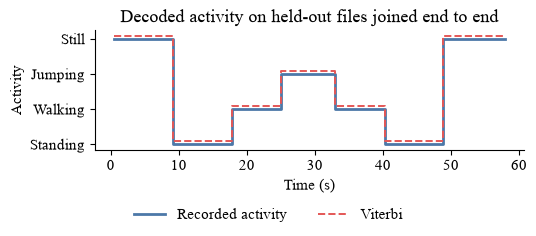

In [9]:
example = decoded_example(model, scaler, pure, mixed)
plot_decoded(
    example["centers"],
    example["truth"],
    example["predicted"],
    ACTIVITIES,
    title=example["title"],
)
print(f"Frame accuracy on this sequence: {example['accuracy']:.3f}")
print("Files:", ", ".join(Path(path).name for path in example["paths"]))

## Without the log

The same pipeline with a plain z-score on the raw features, scored on the same held-out files.

In [10]:
plain_model, plain_scaler, _, _, plain_start = fit_model(splits, log=False)
plain = score_items(plain_model, plain_scaler, pure)
plain_before = score_with_params(plain_model, plain_scaler, pure, plain_start)
print(f"Plain z-score, labeled starting point: {plain_before['frame_accuracy']:.3f}")
print(f"Plain z-score, after Baum-Welch:       {plain['frame_accuracy']:.3f}")
for name, row in zip(ACTIVITIES, plain["metrics"]):
    print(f"  {name:9} sensitivity {row['sensitivity']:.3f}")
print("Transitions learned without the log:")
print(np.round(plain_model.A, 3))

Plain z-score, labeled starting point: 1.000
Plain z-score, after Baum-Welch:       0.862
  standing  sensitivity 0.587
  walking   sensitivity 1.000
  jumping   sensitivity 1.000
  still     sensitivity 0.856
Transitions learned without the log:
[[0.482 0.    0.    0.518]
 [0.    1.    0.    0.   ]
 [0.    0.    1.    0.   ]
 [0.259 0.    0.    0.741]]


## Unseen session

The unseen recordings are a second session on the same phone, about 11 hours after the first (22:29 to 22:36 UTC on 27 October). There are 5 single-activity files per activity, made the same way as the training files, and 2 continuous recordings of about 61 seconds that change activity three to five times. None of them was used to fit the scaler or the model, to name the states, or to choose any setting.

The continuous recordings are labeled from `data/unseen/segments.csv`. Putting the phone down and picking it up are labeled `transition`. Viterbi decodes those windows, so the chain sees the real timeline, but they are not scored. A sample in the table is one scored window.

Activity      Windows  Sensitivity  Specificity   Accuracy
standing          104        0.981        0.995      0.990
walking           147        0.993        0.994      0.990
jumping           124        1.000        0.997      0.990
still             111        0.982        1.000      0.990
Single-activity files: 0.992 on 259 windows, 20 / 20 files right by majority vote
Continuous recordings: 0.987 on 227 scored windows


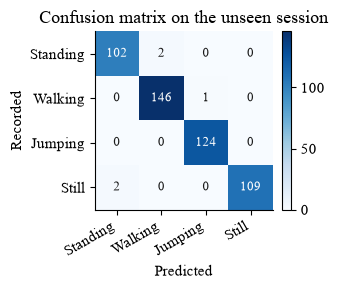

In [11]:
unseen_items = splits["unseen"]
unseen_single = [item for item in unseen_items if item["meta"]["activity"] != "mixed"]
unseen_mixed = [item for item in unseen_items if item["meta"]["activity"] == "mixed"]
unseen = score_items(model, scaler, unseen_items)

print(f"{'Activity':12} {'Windows':>8} {'Sensitivity':>12} {'Specificity':>12} {'Accuracy':>10}")
for name, row in zip(ACTIVITIES, unseen["metrics"]):
    print(
        f"{name:12} {row['support']:8d} {row['sensitivity']:12.3f} "
        f"{row['specificity']:12.3f} {row['overall_accuracy']:10.3f}"
    )
single_score = score_items(model, scaler, unseen_single)
mixed_score = score_items(model, scaler, unseen_mixed)
print(f"Single-activity files: {single_score['frame_accuracy']:.3f} on {single_score['n_frames']} windows, "
      f"{int(single_score['file_accuracy'] * len(unseen_single))} / {len(unseen_single)} files right by majority vote")
print(f"Continuous recordings: {mixed_score['frame_accuracy']:.3f} on {mixed_score['n_frames']} scored windows")
plot_heatmap(
    unseen["confusion"],
    ACTIVITIES,
    "Confusion matrix on the unseen session",
    "Predicted",
    "Recorded",
    "d",
);

Recording 1: 0.983 on 115 scored windows, 6 transition windows not scored
Recording 2: 0.991 on 112 scored windows, 9 transition windows not scored


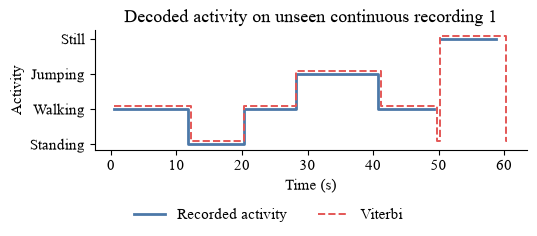

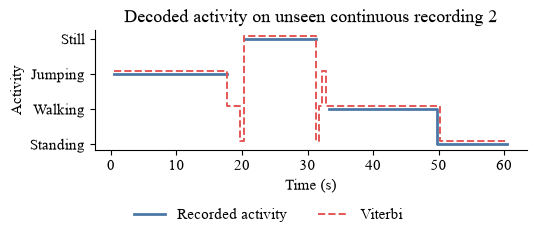

In [12]:
for number, item in enumerate(unseen_mixed, start=1):
    path = decode(item)
    scored = item["labels"] >= 0
    plot_decoded(
        item["centers"],
        item["labels"],
        path,
        ACTIVITIES,
        title=f"Decoded activity on unseen continuous recording {number}",
    )
    accuracy = np.mean(path[scored] == item["labels"][scored])
    print(f"Recording {number}: {accuracy:.3f} on {scored.sum()} scored windows, "
          f"{(~scored).sum()} transition windows not scored")

In [13]:
print("Every unseen window the model gets wrong")
for item in unseen_items:
    path = decode(item)
    wrong = np.where((item["labels"] >= 0) & (path != item["labels"]))[0]
    for i in wrong:
        print(
            f"  {Path(item['meta']['path']).name:14} window centred at {item['centers'][i]:5.1f} s: "
            f"recorded {ACTIVITIES[item['labels'][i]]}, decoded {ACTIVITIES[path[i]]}"
        )

Every unseen window the model gets wrong
  still_001.csv  window centred at   0.5 s: recorded still, decoded standing
  still_001.csv  window centred at   1.0 s: recorded still, decoded standing
  mixed_001.csv  window centred at  12.0 s: recorded standing, decoded walking
  mixed_001.csv  window centred at  41.0 s: recorded walking, decoded jumping
  mixed_002.csv  window centred at  50.0 s: recorded standing, decoded walking


## Reading the result

On the 40 held-out files the Viterbi path is right on all 581 windows, and every file is right by majority vote. Sensitivity and specificity are 1.000 for every activity. The labeled starting point already scores 1.000, and Baum-Welch converges in 4 iterations without changing a held-out label. The held-out files come from the same person, phone, and hour as the training files. So the result says the four activities are separable here, not that the model will hold for another person or another way of carrying the phone.

The unseen session is the harder test. It was recorded about 11 hours later, and none of it was used to fit or tune the model. Accuracy is 0.990 on its 486 scored windows: 0.992 on the 20 single-activity files and 0.987 on the two continuous recordings. Five windows are wrong. Three are the window that straddles a change of activity, which holds half of each, so its label depends on where the change is marked. The other two are the first second of one still file, called standing: the phone was still settling after it was put down, with five times the motion of the rest of the file. So the four activities stay apart across two sessions on this phone. That still says nothing about another person or another phone.

Standing and still are the hard pair. The phone was flat in both, so its orientation does not tell them apart. Only the size of the motion does: about 0.1 m/s² of sway against about 0.01 m/s² of sensor noise. Without the log, Baum-Welch drags held-out accuracy from 1.000 to 0.862. Standing sensitivity falls to 0.587, and the model learns a standing-to-still probability of about 0.5, although no recording contains that change. With the log, the two states stay apart.

The transition matrix is diagonal. Self-transitions are 0.998 for standing, 0.997 for still, and 1.000 for walking and jumping. That is all single-activity recordings can teach: every pair of consecutive windows inside a file is the same activity. The only off-diagonal mass is what EM assigns when a quiet standing window looks partly like still. The joined sequence is still decoded without error, because the emissions differ so much that one switch costs less than staying in the wrong state. Realistic transition probabilities need recordings that change activity, such as still to standing to walking, labeled at each change. Once those are in `data/sequences` with activity `mixed` in the manifest, the same code learns from them, and the decoded-path figure uses one of them. The unseen continuous recordings show the same thing on real changes. Every change between activities has a learned probability near 10⁻⁸, yet Viterbi switches within one window of each. They stay out of training, so the matrix above still reflects single-activity files only.